In [7]:
SEED = 0

In [8]:
%config InlineBackend.figure_format = 'svg'

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, balanced_accuracy_score

np.random.seed(SEED)
plt.style.use('yl.mplstyle')

figures_path = "figures/"


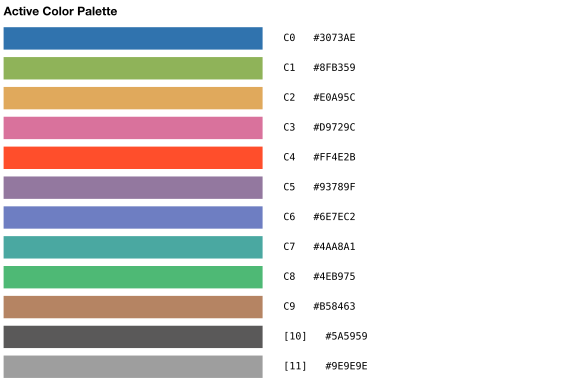

In [10]:
import matplotlib.patches as patches

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

fig, ax = plt.subplots(figsize=(8, len(colors) * 0.45), layout="constrained")

for i, hex_code in enumerate(colors):
    # Ensure hex code starts with '#'
    color_str = hex_code if hex_code.startswith('#') else f'#{hex_code}'
    label_prefix = f"C{i}" if i < 10 else f"[{i}]"
    
    # Draw color swatch rectangle
    rect = patches.Rectangle((0, i), 1, 0.75, facecolor=color_str, edgecolor='none')
    ax.add_patch(rect)
    
    # Label with C0-C9 shorthand and hex code
    ax.text(1.08, i + 0.375, f"{label_prefix}   {color_str.upper()}", va='center', fontsize=10, family='monospace')

ax.set_xlim(0, 2.2)
ax.set_ylim(-0.2, len(colors))
ax.invert_yaxis()  # Put C0 at the top
ax.axis('off')
ax.set_title("Active Color Palette", loc='left', fontsize=12, fontweight='bold')

plt.show()

In [11]:
data = np.load("data/learning_set.npz")
series = data["series"] # shape=(3463, 3, 128): 3463 objects; semi-major axis a, eccentricity, drag force term; 128 days
label = data["label"]   # shape=(3463,)
split = data["split"]   # shape=(3463,)

cat = pd.read_csv("data/catalogue.csv")
for object_id, rows in cat.groupby("object_id"):
    rows = rows.sort_values("epoch_day")
    t, a = rows["epoch_day"].to_numpy(), rows["a_km"].to_numpy()

# Step 1

## 1.1. 
Count the objects in each split (training, validation, test), and the class frequencies in the training and validation sets. 

Then build a majority-class baseline: a classifier that predicts for every object the class that is most frequent in the training set. 

Evaluate it on the validation set with two metrics:
- The accuracy: the fraction of validation objects whose predicted label is the
label in the file.
- The balanced accuracy: the fraction of correctly predicted objects within
each class, averaged over the four classes.

In [12]:
n_learningset = len(label)
n_learningset

3463

In [13]:
np.unique(split)

array([0, 1, 2], dtype=int8)

In [14]:
np.unique(label)

array([-1,  0,  1,  2,  3], dtype=int8)

In [15]:
train_counts = [np.sum((label == c) & (split == 0)) for c in range(4)]
val_counts = [np.sum((label == c) & (split == 1)) for c in range(4)]
test_counts = np.count_nonzero(split == 2)

In [16]:
print(f"Number of training objects: {train_counts}")
for c in range(4):
    print(f"\t class {c}: {np.sum((label==c)&(split==0))}")
    
print(f"Number of validation objects: {val_counts}")
for c in range(4):
    print(f"\t class {c}: {np.sum((label==c)&(split==1))}")
    
print(f"Number of test objects: {test_counts}")

Number of training objects: [np.int64(421), np.int64(455), np.int64(595), np.int64(606)]
	 class 0: 421
	 class 1: 455
	 class 2: 595
	 class 3: 606
Number of validation objects: [np.int64(146), np.int64(150), np.int64(202), np.int64(193)]
	 class 0: 146
	 class 1: 150
	 class 2: 202
	 class 3: 193
Number of test objects: 695


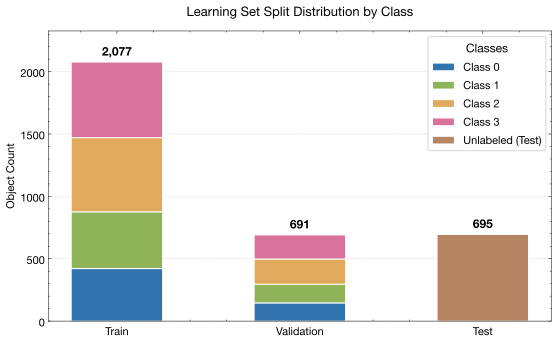

In [17]:
categories = ['Train', 'Validation', 'Test']

fig, ax = plt.subplots(figsize=(8, 5))

bottom_train = 0
bottom_val = 0

# plot stacked bar for train and val
for c in range(4):
    ax.bar(
        ['Train', 'Validation'],
        [train_counts[c], val_counts[c]],
        bottom=[bottom_train, bottom_val],
        label=f'Class {c}',
        edgecolor='white',
        width=0.5
    )
    bottom_train += train_counts[c]
    bottom_val += val_counts[c]

# plot for test
ax.bar(
    ['Test'],
    [test_counts],
    label='Unlabeled (Test)',
    color='C9',
    edgecolor='white',
    width=0.5
)

# add total count labels on top of each bar
totals = [sum(train_counts), sum(val_counts), test_counts]
for i, total in enumerate(totals):
    ax.text(
        i,
        total + (max(totals) * 0.015),
        f'{total:,}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

# 6. Formatting and styling
ax.set_ylabel('Object Count', fontsize=11)
ax.set_title('Learning Set Split Distribution by Class', pad=15)
ax.set_ylim(0, max(totals) * 1.12)  # Give headroom for the top text labels
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title='Classes', frameon=True)

plt.tight_layout()
plt.savefig(figures_path+"1.1.png", pad_inches=0.3)
plt.show()

Building a majority-class baseline model and evaluating its performance

In [18]:
def maj_class_baseline(train_classes):
    classes, counts = np.unique(train_classes, return_counts=True)
    return classes[np.argmax(counts)]

train_classes = label[split==0]
maj_class_pred = maj_class_baseline(train_classes)

In [19]:
y_true = label[split==1]
y_pred = np.full_like(label[split==1], maj_class_pred)

acc = accuracy_score(y_true=y_true, y_pred=y_pred)
balacc = balanced_accuracy_score(y_true=y_true, y_pred=y_pred)

# The accuracy: the fraction of validation objects whose predicted label is the label in the file.
print(f"Major-class baseline model accuracy: \t\t{acc:,.5f}")
# The balanced accuracy: the fraction of correctly predicted objects within each class, averaged over the four classes.
print(f"Major-class baseline model balanced accuracy: \t{balacc}")

Major-class baseline model accuracy: 		0.27931
Major-class baseline model balanced accuracy: 	0.25


## 1.2.
Plot 𝑎, 𝑒 and the drag term 𝛽 against the day for two or three objects of each class, chosen by you, one panel per quantity. 

Then engineer four scalar features from each object’s series:
- The mean of 𝑎 over the 128 days: the altitude.
- The decay rate: the slope of a straight line fitted by least squares to 𝑎 against
the day, in metres per day.
- The number of re-boosts: the days on which 𝑎 rises by more than a threshold;
choose the threshold from your plots.
- The mean of the drag term.

Which classes does each feature help to separate, and why (Sec. 3)? Steps 3 and 4
use these features again

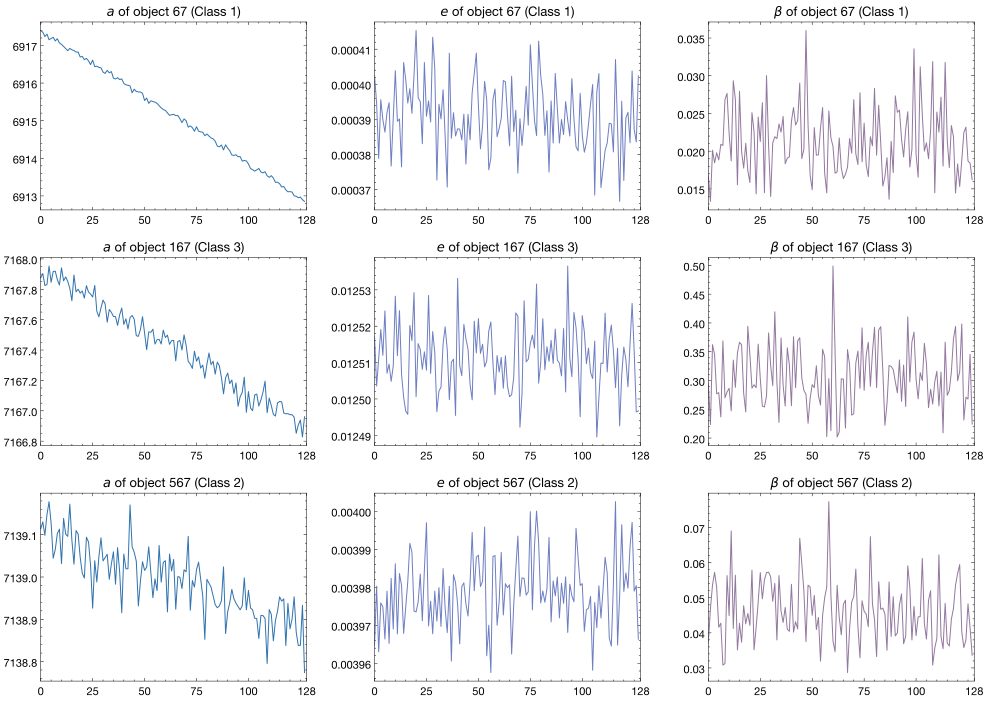

In [20]:
obj_1 = 67
obj_2 = 167
obj_3 = 567

t = np.arange(128) 

fig, ax = plt.subplots(3, 3, figsize=(14, 10))
xticks = [0, 25, 50, 75, 100, 128]

for i, obj in enumerate([obj_1, obj_2, obj_3]):
    a_1 = series[obj][0]
    e_1 = series[obj][1]
    beta_1 = series[obj][2]
    obj_label = label[obj]
    
    ax[i, 0].plot(t, a_1, color='C0')
    ax[i, 0].set_title(rf"$a$ of object {obj} (Class {obj_label})")
    ax[i, 0].set_xlim(0, 128)
    ax[i, 0].set_xticks(xticks)
    
    ax[i, 1].plot(t, e_1, color='C6')
    ax[i, 1].set_title(rf"$e$ of object {obj} (Class {obj_label})")
    ax[i, 1].set_xlim(0, 128)
    ax[i, 1].set_xticks(xticks)
    
    ax[i, 2].plot(t, beta_1, color='C5')
    ax[i, 2].set_title(rf"$\beta$ of object {obj} (Class {obj_label})")
    ax[i, 2].set_xlim(0, 128)
    ax[i, 2].set_xticks(xticks)

plt.tight_layout()
plt.savefig(figures_path+"1.2.png", pad_inches=0.3)
plt.show()

In [21]:
# The mean of 𝑎 over the 128 days: the altitude.
a_means = [np.mean(series[obj][0]) for obj in range(n_learningset)]

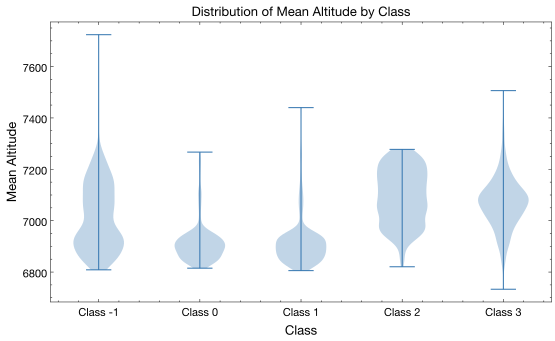

In [22]:
unique_labels = np.unique(label)

d = [np.array(a_means)[label == l] for l in unique_labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(d, positions=unique_labels)
ax.set_xticks(unique_labels)
ax.set_xticklabels([f"Class {l}" for l in unique_labels])
ax.set_xlabel("Class")
ax.set_ylabel("Mean Altitude")
ax.set_title("Distribution of Mean Altitude by Class")

plt.tight_layout()
plt.show()

In [23]:
# The decay rate: the slope of a straight line fitted by least squares to 𝑎 against the day, in metres per day.
def get_decay(obj):
    m, c = np.polyfit(t, series[obj][0],1) # get gradient of least squares fit
    return m
decay_rates = [get_decay(obj) for obj in range(n_learningset)]

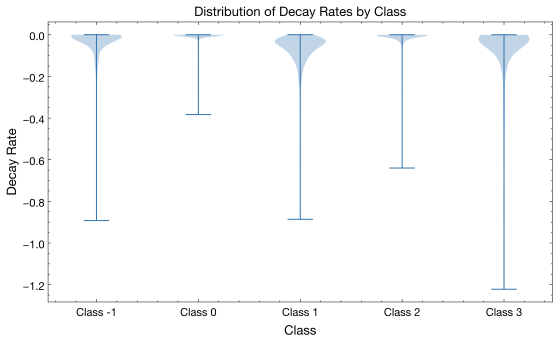

In [24]:
d = [np.array(decay_rates)[label == l] for l in unique_labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(d, positions=unique_labels)
ax.set_xticks(unique_labels)
ax.set_xticklabels([f"Class {l}" for l in unique_labels])
ax.set_xlabel("Class")
ax.set_ylabel("Decay Rate")
ax.set_title("Distribution of Decay Rates by Class")

plt.tight_layout()
plt.show()

Examine how boosts are distributed to select a suitable threshold for re-boosts

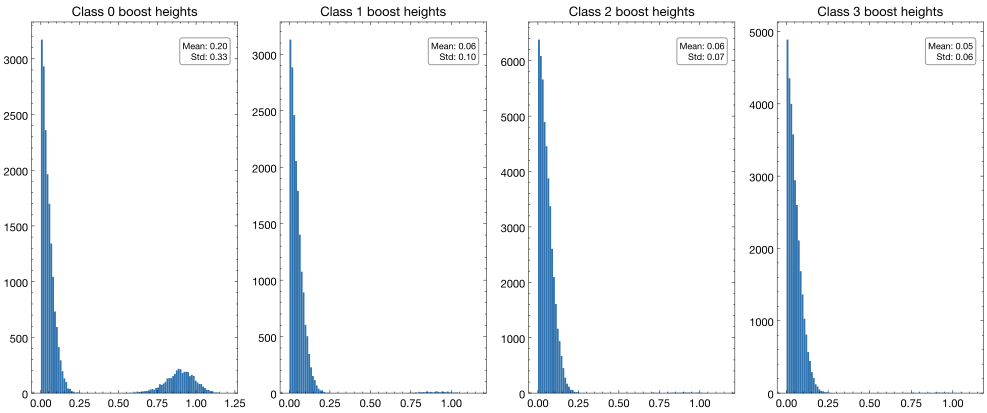

Boosts are counted whenever there is an altitude increase


In [25]:
fig, ax = plt.subplots(1, 4, figsize=(14, 6))

for l in range(4):
    boost = []
    for obj in np.where(label==l)[0]:
        for i in range(1, len(series[obj][0])):
            alt_change = series[obj][0][i] - series[obj][0][i-1]
            if alt_change>0:
                boost.append(alt_change)
                
    ax[l].hist(boost, bins=100)
    ax[l].set_title(f"Class {l} boost heights")
    
    mean_val = np.mean(boost)
    std_val = np.std(boost)
    text_str = f"Mean: {mean_val:.2f}\nStd: {std_val:.2f}"
    
    # Place text box in the top right corner using axes coordinates
    props = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
    ax[l].text(0.95, 0.95, text_str, transform=ax[l].transAxes, fontsize=9,
                verticalalignment='top', horizontalalignment='right', bbox=props)

plt.tight_layout()
plt.show()
print("Boosts are counted whenever there is an altitude increase")

From the previous plot, it is apparent that Class 0 represents an active payload as the boost heights are significantly greater than the other classes. Hence, I shall use the value of the mean=0.20 of Class 0 boosts as the minimum threshold to count as a re-boost.

In [26]:
# The number of re-boosts: the days on which 𝑎 rises by more than a threshold; choose the threshold from your plots.
threshold = 0.2
def count_boost(obj):
    n_boost = 0
    for i in range(1, len(series[obj][0])):
        alt_change = series[obj][0][i] - series[obj][0][i-1]
        if alt_change>threshold:
            n_boost += 1
    return n_boost

n_reboosts = [count_boost(obj) for obj in range(n_learningset)]

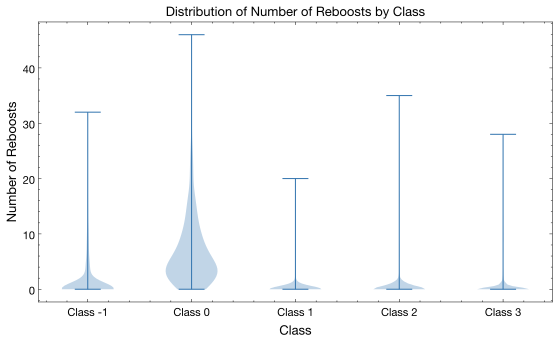

In [27]:
d = [np.array(n_reboosts)[label == l] for l in unique_labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(d, positions=unique_labels)
ax.set_xticks(unique_labels)
ax.set_xticklabels([f"Class {l}" for l in unique_labels])
ax.set_xlabel("Class")
ax.set_ylabel("Number of Reboosts")
ax.set_title("Distribution of Number of Reboosts by Class")

plt.tight_layout()
plt.show()

In [28]:
# The mean of the drag term.
drag_means = [np.mean(series[obj][2]) for obj in range(n_learningset)]

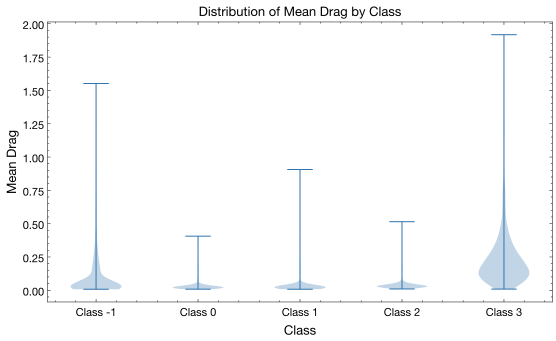

In [29]:
d = [np.array(drag_means)[label == l] for l in unique_labels]

fig, ax = plt.subplots(figsize=(8, 5))
ax.violinplot(d, positions=unique_labels)
ax.set_xticks(unique_labels)
ax.set_xticklabels([f"Class {l}" for l in unique_labels])
ax.set_xlabel("Class")
ax.set_ylabel("Mean Drag")
ax.set_title("Distribution of Mean Drag by Class")

plt.tight_layout()
plt.show()

## 1.3.
Some labels in the training and validation sets are wrong, and can be considered noise. For each feature, plot one histogram per class on the same axes. An object whose feature value lies in the range of another class is a candidate for a wrong label, e.g., an active payload with no re-boost, or a fragment with the drag term of a payload. 

Describe your selection rules, count the candidates, and report the count and its fraction of the labelled objects.

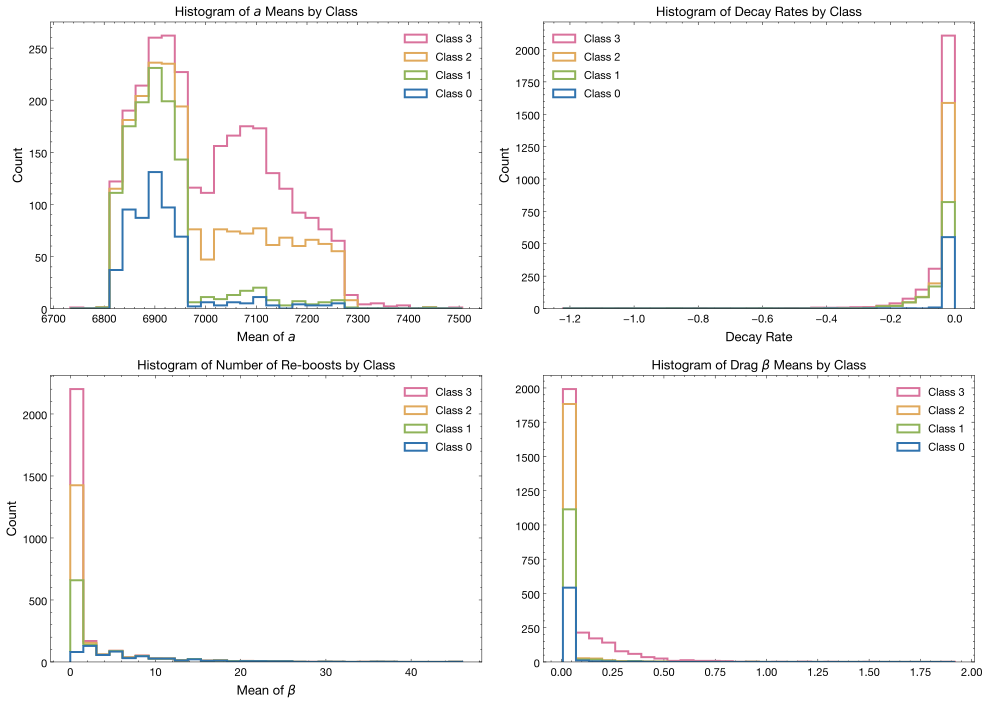

In [30]:
legend_labels = [f"Class {c}" for c in unique_labels[1:]]

fig, ax = plt.subplots(2, 2, figsize=(14, 10))

d = [np.array(a_means)[label == l] for l in unique_labels]
ax[0][0].hist(d[1:], 30, histtype="step", stacked=True, label=legend_labels, linewidth=2)
ax[0][0].legend()
ax[0][0].set_title(r"Histogram of $a$ Means by Class")
ax[0][0].set_ylabel("Count")
ax[0][0].set_xlabel(r"Mean of $a$")

d = [np.array(decay_rates)[label == l] for l in unique_labels]
ax[0][1].hist(d[1:], 30, histtype="step", stacked=True, label=legend_labels, linewidth=2)
ax[0][1].legend()
ax[0][1].set_title(r"Histogram of Decay Rates by Class")
ax[0][1].set_ylabel("Count")
ax[0][1].set_xlabel(r"Decay Rate")

d = [np.array(n_reboosts)[label == l] for l in unique_labels]
ax[1][0].hist(d[1:], 30, histtype="step", stacked=True, label=legend_labels, linewidth=2)
ax[1][0].legend()
ax[1][0].set_title(r"Histogram of Number of Re-boosts by Class")
ax[1][0].set_ylabel("Count")
ax[1][0].set_xlabel(r"Number of Re-boosts")

d = [np.array(drag_means)[label == l] for l in unique_labels]
ax[1][1].hist(d[1:], 30, histtype="step", stacked=True, label=legend_labels, linewidth=2)
ax[1][1].legend()
ax[1][1].set_title(r"Histogram of Drag $\beta$ Means by Class")
ax[1][0].set_ylabel("Count")
ax[1][0].set_xlabel(r"Mean of $\beta$")

plt.tight_layout()
plt.savefig(figures_path+"1.3.png", pad_inches=0.3)
plt.show()

What we know:

- Debris (DEB): 400 to 900km AGL --> $a$ should range from 6378+400km to 6378+900km --> a roughly 7028±250 km
- Debris (DEB): Decay rate is largest for light objects with a large surface, such as fragments, and for low orbits where air is denser
    - Hence Class 1 is most likely the DEB class (because high drag, low altitude)
- Active payload (PAY): $a(t)$ is a sawtooth, so number of re-boosts should be intentional and significant
    - Hence Class 0 is most likely the Active payload class

Can't distinguish if Class 2 or Class 3 belongs to a Dead payload (PAY) or Rocket body (R/B)

# <font color="yellow">*TODO*</font>

In [31]:
# discriminate Class 0: if number of re-boosts is less than mean-1sigma, AND low 

## 1.4.
Build the input vectors of steps 2 and 3: one row of 3 ×128 numbers per object, the 128 values of 𝑎, then those of 𝑒, then those of the drag term. Standardise every column with the mean and standard deviation of the training set. Keep every object and its label as given in steps 2 and 3; the candidates of question 3 are used in step 3, question 4.

In [32]:
train_x = series[(label!=-1) & (split==0)] # shape (2077, 3, 128)
train_x = train_x.reshape(train_x.shape[0], -1) # shape (2077, 384)
train_y = label[split==0]

val_x = series[(label!=-1) & (split==1)]
val_x = val_x.reshape(val_x.shape[0], -1)
val_y = label[split==1]

assert len(train_x) == len(train_y), "train set x and y counts don't match!"
assert len(val_x) == len(val_y), "val set x and y counts don't match!"

In [33]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_x = scaler.fit_transform(train_x)
val_x = scaler.transform(val_x)

# Step 2

## 2.1.

Train a multiclass logistic-regression classifier with an L2 regulariser on the training set. 

Its loss is Eq. (3) below; $C$ is the inverse regularisation strength, so a small $C$ is a strong regulariser. Use class weights inversely proportional to the class frequencies, since the classes are imbalanced (scikit-learn): LogisticRegression with class_weight="balanced". 

$$
\begin{gathered}
J(W, \boldsymbol{b}) = \frac{1}{N} \sum_{n=1}^{N} s_n \, \text{CE}_n + \frac{\lambda}{2} \|W\|^2, \qquad \lambda = \frac{1}{CN}, \\[10pt]
\text{CE}_n = -\ln \frac{\exp(z_{n, y_n})}{\sum_{k=1}^{4} \exp(z_{n, k})}, \qquad \boldsymbol{z}_n = W^\top \boldsymbol{x}_n + \boldsymbol{b},
\end{gathered}
$$

Train one model for each $C = 10^{-4}, \ldots, 10^{2}$, in factors of ten, and report the balanced accuracy on the training set and on the validation set for each $C$, in one table or one plot. Select the $C$ with the highest validation balanced accuracy and say which it is.


In [34]:
Cs = [10**i for i in range(-4, 3)]
Cs

[0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

In [35]:
from sklearn.linear_model import LogisticRegression

train_balaccs = []
val_balaccs = []

for C in Cs:
    LRclassifier = LogisticRegression(
        random_state=SEED, 
        l1_ratio=0, 
        C=C, 
        class_weight="balanced", 
        max_iter=10000)
    LRclassifier.fit(train_x, train_y)

    train_pred_y = LRclassifier.predict(train_x)
    train_balaccs.append(balanced_accuracy_score(y_true=train_y, y_pred=train_pred_y))

    val_pred_y = LRclassifier.predict(val_x)
    val_balaccs.append(balanced_accuracy_score(y_true=val_y, y_pred=val_pred_y))

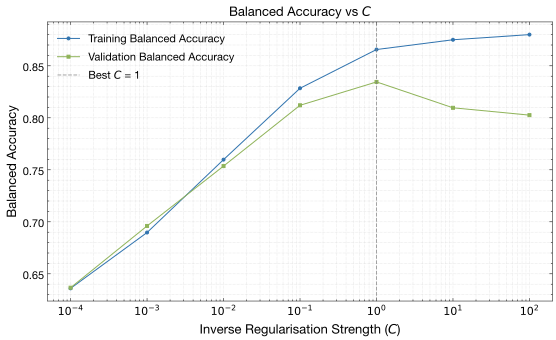

Best C: 1 with Validation Balanced Accuracy: 0.83449


In [36]:
# Find the best C based on validation balanced accuracy
best_idx = int(np.argmax(val_balaccs))
best_C = Cs[best_idx]
best_val_acc = val_balaccs[best_idx]

# Plot results
plt.figure(figsize=(8, 5))
plt.plot(Cs, train_balaccs, marker='o', label='Training Balanced Accuracy')
plt.plot(Cs, val_balaccs, marker='s', label='Validation Balanced Accuracy')
plt.axvline(best_C, color='gray', linestyle='--', alpha=0.7, label=rf'Best $C$ = {best_C:g}')

plt.xscale('log')
plt.xticks(Cs, [f'$10^{{{int(np.log10(c))}}}$' for c in Cs])
plt.xlabel('Inverse Regularisation Strength ($C$)')
plt.ylabel('Balanced Accuracy')
plt.title('Balanced Accuracy vs $C$')
plt.legend()
plt.grid(True, which='both', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(figures_path+"2.1.png", pad_inches=0.3)
plt.show()

print(f"Best C: {best_C:g} with Validation Balanced Accuracy: {best_val_acc:.5f}")

## 2.2

The logit of each class is a linear combination of the inputs. Take the 128 weights on $a(t)$ of each class, at your $C$:

- Plot them against the day, one line per class, and describe their shape.
- The linear combination $\sum_t w(t)\,a(t)$ over the 128 days is one number per object, like the features of step 1. Say which feature of step 1 it resembles. Check it: compute it for the training objects and its correlation with that feature.

In [37]:
LRclassifier = LogisticRegression(
    random_state=SEED, 
    l1_ratio=0, 
    C=best_C, # which was 1 
    class_weight="balanced", 
    max_iter=10000)
LRclassifier.fit(train_x, train_y)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

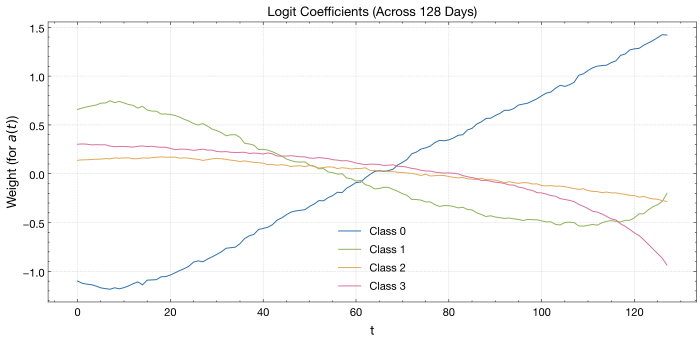

In [38]:
plt.figure(figsize=(10, 5))

for i in range(4):
    a_weights = LRclassifier.coef_[i][:128]
    plt.plot(t, a_weights, label=f"Class {i}")

plt.xlabel("t")
plt.ylabel(r"Weight (for $a(t)$)")
plt.title("Logit Coefficients (Across 128 Days)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(figures_path+"2.2.png", pad_inches=0.3)
plt.show()

# <font color="yellow">*TODO*</font>

- Class 0 (likely Active payload) shows a steady rise over the 128 days, perhaps showing a general rise in altitude
- Class 1 (likely Debris) shows almost an oscillation over the 128 days, perhaps showing that the object was drifting about in low earth orbit

In [39]:
# consisting of features of train set only

linear_comb = train_x[:, :128] @ LRclassifier.coef_[:, :128].T 

The linear combination $\sum_t w(t)\,a(t)$ will most likely resemble that of the decay rate previously calculated, as we are measuring the rate of change in altitude.

In [40]:
for k in range(4):
    r = np.corrcoef(linear_comb[:, k], np.array(decay_rates)[split==0])
    r = r[0][1]
    print(f"Class {k} correlation: {r:.5f}")

Class 0 correlation: 0.88141
Class 1 correlation: -0.98163
Class 2 correlation: -0.13191
Class 3 correlation: -0.87724


# <font color="yellow">*TODO*</font>

## 2.3.

Implement gradient descent for the loss 

$$
\begin{gathered}
J(W, \boldsymbol{b}) = \frac{1}{N} \sum_{n=1}^{N} s_n \, \text{CE}_n + \frac{\lambda}{2} \|W\|^2, \qquad \lambda = \frac{1}{CN}, \\[10pt]
\text{CE}_n = -\ln \frac{\exp(z_{n, y_n})}{\sum_{k=1}^{4} \exp(z_{n, k})}, \qquad \boldsymbol{z}_n = W^\top \boldsymbol{x}_n + \boldsymbol{b},
\end{gathered}
$$

- where $N$ is the number of training objects, 
- $\mathbf{x}_n$ the input vector of object $n$ and $y_n$ its label in the file, 
- $W$ holds the weights (one column per class) and $\mathbf{b}$ the biases, 
- $\mathbf{z}_n$ is the vector of the four logits of object $n$, 
- $\text{CE}_n$ its cross-entropy, the negative log of the softmax probability given to its label, 
- $s_n = N/(4N_{y_n})$ with $N_{y_n}$ the number of training objects of the class of object $n$, and
- $\|\mathbf{W}\|^2$ is the sum of the squared weights (the biases are not regularised). 

Gradient descent updates the parameters $\boldsymbol{\theta} = (\mathbf{W}, \mathbf{b})$ as $\boldsymbol{\theta} \leftarrow \boldsymbol{\theta} - \eta \nabla J(\boldsymbol{\theta})$, with a fixed learning rate $\eta$, from $\boldsymbol{\theta} = 0$; write it yourself, with no library minimiser. It uses only the gradient,

$$ 
\begin {gathered}
\nabla_W J = \frac{1}{N} X^{\top} [ s \odot (P - Y) ] + \lambda W, \qquad \nabla_b J = \frac{1}{N} \sum_{n=1}^{N} s_n (\mathbf{p}_n - \mathbf{y}_n)
\end {gathered}
$$

- where the rows of $X$ are the input vectors, 
- the rows of $P$ the softmax probabilities $p_n$ of each object, 
- the rows of $Y$ the one-hot labels $y_n$, and 
- $s\odot$ multiplies row $n$ by $s_n$.

    - The learning rate. Gradient descent converges only for $\eta < 2/L$, where $L$ is the largest curvature of $J$: the largest eigenvalue of its Hessian $H$, the matrix of second derivatives. Use $\eta = 1/L$. Compute $L$ once for each $C$, before the runs, and from gradients alone: the product of $H$ with a vector $\mathbf{v}$ is a finite difference of the gradient, $H\mathbf{v} \approx [\nabla J(\theta + \epsilon\mathbf{v}) - \nabla J(\theta - \epsilon\mathbf{v})]/(2\epsilon)$ with $\epsilon$ about $10^{-6}$, and power iteration (start from a random $\mathbf{v}$ and replace $\mathbf{v}$ by $H\mathbf{v}/||H\mathbf{v}||$ a hundred times) makes $||H\mathbf{v}||$ settle at $L$. Evaluate it at the minimum of $J$, $\theta^{\star}$, which you take from a library solver run to convergence (LogisticRegression with the same $C$ and class weights, its weights put into Eq. (3)); $J^{\star} = J(\theta^{\star})$ is the minimum of the loss. Report $L$ at $C = 10^{-2}$ and at your $C$.
    - The runs. At $C = 10^{-2}$ and at your $C$, run 5,000 iterations with $\eta = 1/L$ and report $J - J^{\star}$ at the end. Report also the condition number $\kappa = L/\lambda$ for both values of $C$: the ratio of the largest to the smallest curvature of $J$, the smallest being $\lambda$.
    - Above the limit. Run 5,000 iterations with $\eta = 2.5/L$ at your $C$ and report what happens.
    - Momentum. Add Nesterov's momentum [7]: the velocity $\mathbf{v} \leftarrow \theta\mathbf{v} - \eta \nabla J(W + \theta\mathbf{v})$, then $W \leftarrow W + \mathbf{v}$ (the same for $\mathbf{b}$), with $\eta = 1/L$ and $\theta = (\sqrt{\kappa} - 1)/(\sqrt{\kappa} + 1)$. Run 5,000 iterations at your $C$ and report $J - J^{\star}$, against plain gradient descent.